# Vision foundation models in practice: CLIP 

In this notebook we play with the CLIP model.

| Part | Model | What it learned from | What we will do |
|---|---|---|---|
| 1 | **CLIP** (OpenAI, 2021) | 400M image-caption pairs from the web | **Zero-shot classification** and text→image search |

**Hardware.** Everything runs on a laptop CPU (a few seconds per image). A GPU (or Colab) is faster but not needed.
We use the small version: CLIP ViT-B/32 (~600 MB download).

## 0. Setup

In [4]:
# # Uncomment on a fresh environment (Colab already has most of these)
!pip install -q torch torchvision transformers scikit-image matplotlib pillow requests


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [5]:
import io, requests, numpy as np, torch, matplotlib.pyplot as plt
import torch.nn.functional as F
from PIL import Image
from skimage import data as skdata

torch.set_grad_enabled(False)          # inference only
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

Using device: mps


### Some test images
We use a few images that ship with `scikit-image` (they work offline) plus one COCO image from the web.
You can add your own with `load_image("path/or/url.jpg")`.

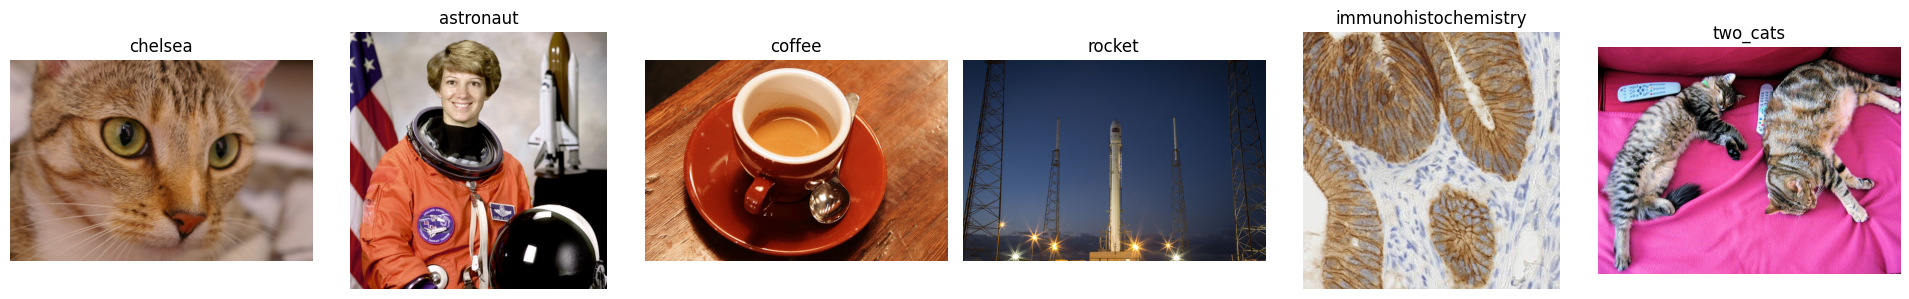

In [6]:
def load_image(src):
    # Load a PIL RGB image from a local path or URL.
    if str(src).startswith("http"):
        r = requests.get(src, timeout=15); r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert("RGB")
    return Image.open(src).convert("RGB")

images = {}
for name in ["chelsea", "astronaut", "coffee", "rocket", "immunohistochemistry"]:
    try:
        images[name] = Image.fromarray(getattr(skdata, name)()).convert("RGB")
    except Exception as e:
        print("skipping", name, "->", e)

try:   # the famous "two cats on a couch" COCO image
    images["two_cats"] = load_image("http://images.cocodataset.org/val2017/000000039769.jpg")
except Exception as e:
    print("Could not download COCO image (offline?)", e)

fig, axes = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3))
for ax, (k, im) in zip(axes, images.items()):
    ax.imshow(im); ax.set_title(k); ax.axis("off")
plt.tight_layout(); plt.show()

---
# CLIP: zero-shot classification

**Idea.** CLIP has two encoders, one for images and one for text, trained so that a picture and its caption land close together in a shared embedding space (contrastive learning).

**Zero-shot classification** then needs no training at all:
1. Write each class name as a sentence, e.g. `"a photo of a cat"`, `"a photo of a dog"`.
2. Encode the image and all sentences.
3. Compute cosine similarity between the image and each sentence, apply softmax → class probabilities.

The "classifier" is just a list of strings. Change the strings, change the classifier.

In [7]:
from transformers import CLIPModel, CLIPProcessor

clip_name = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_name).to(device).eval()
clip_proc  = CLIPProcessor.from_pretrained(clip_name)
print(f"CLIP parameters: {sum(p.numel() for p in clip_model.parameters())/1e6:.0f} M")

/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1127 20:16:59.191000 48347 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 23096.32it/s]


CLIP parameters: 151 M


In [8]:
def _as_tensor(out):   # newer transformers versions may return an output object instead of a tensor
    return out if torch.is_tensor(out) else out.pooler_output

def clip_embed_images(pil_images):
    inputs = clip_proc(images=pil_images, return_tensors="pt").to(device)
    emb = _as_tensor(clip_model.get_image_features(**inputs))
    return F.normalize(emb, dim=-1)

def clip_embed_texts(texts):
    inputs = clip_proc(text=texts, return_tensors="pt", padding=True).to(device)
    emb = _as_tensor(clip_model.get_text_features(**inputs))
    return F.normalize(emb, dim=-1)

def zero_shot(image, labels, template="a photo of a {}."):
    # Returns a probability for each label.
    img_emb = clip_embed_images([image])                       # (1, D)
    txt_emb = clip_embed_texts([template.format(l) for l in labels])  # (C, D)
    logits = clip_model.logit_scale.exp() * img_emb @ txt_emb.T       # (1, C), scaled cosine sim
    return logits.softmax(dim=-1)[0].cpu().numpy()

def show_zero_shot(image, labels, template="a photo of a {}.", title=None):
    p = zero_shot(image, labels, template)
    order = np.argsort(p)
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1, 1.4]})
    a0.imshow(image); a0.axis("off"); a0.set_title(title or "")
    a1.barh(np.array(labels)[order], p[order], color="#3b6ea8")
    a1.set_xlim(0, 1); a1.set_xlabel("probability"); a1.set_title(f'template: "{template}"')
    for i, v in enumerate(p[order]):
        a1.text(min(v + 0.02, 0.9), i, f"{v:.2f}", va="center")
    plt.tight_layout(); plt.show()

### 1.1 A first zero-shot classifier

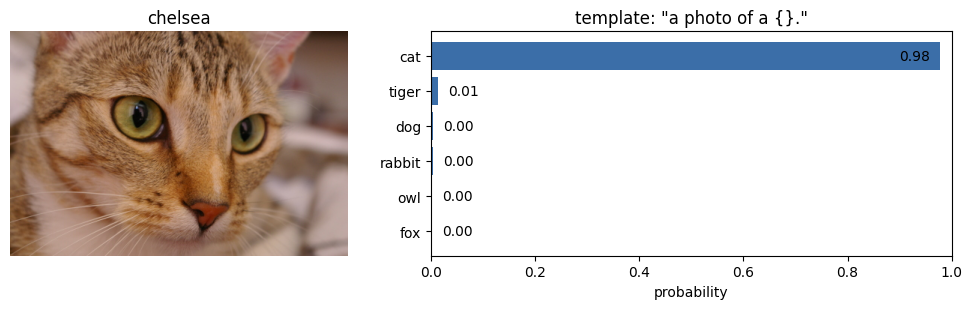

In [9]:
animals = ["cat", "dog", "tiger", "rabbit", "fox", "owl"]
show_zero_shot(images["chelsea"], animals, title="chelsea")

### 1.2 The labels are the classifier - ask different questions about the same image
Nothing was retrained between these cells. We only changed the text.

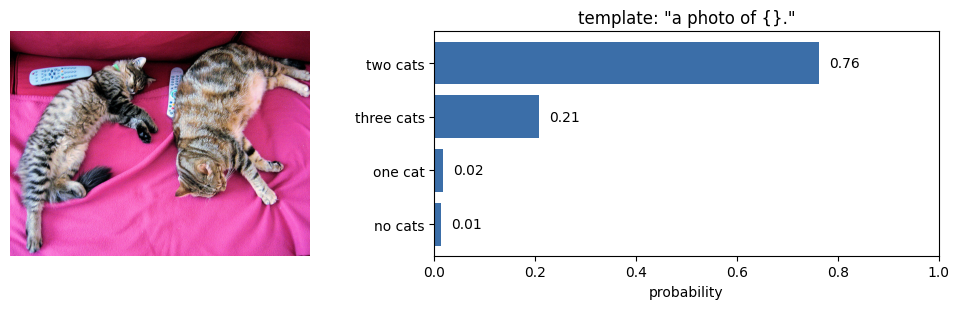

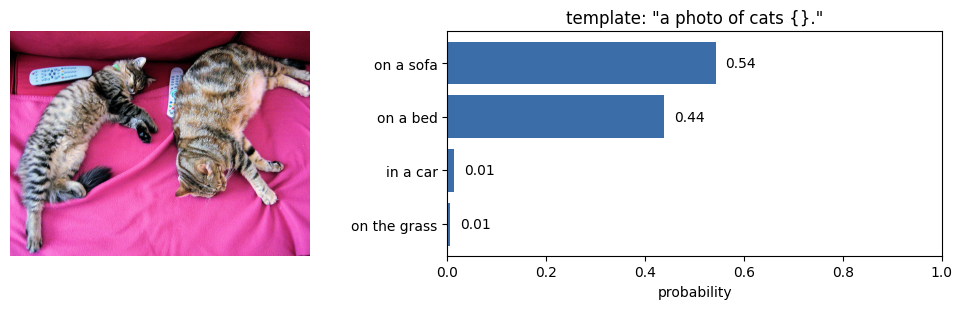

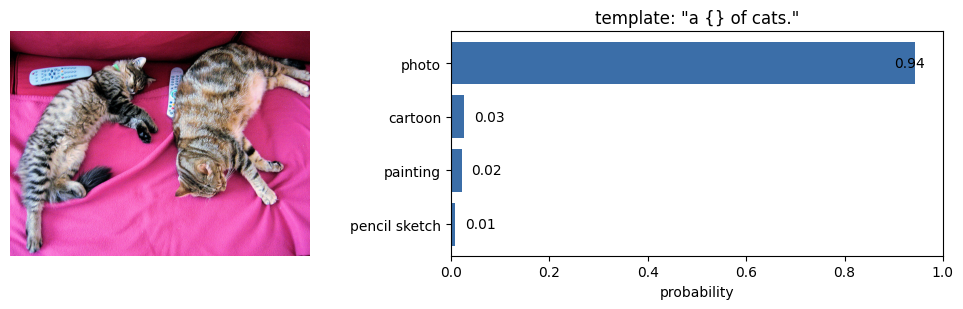

In [10]:
img = images.get("two_cats", images["chelsea"])
show_zero_shot(img, ["one cat", "two cats", "three cats", "no cats"], template="a photo of {}.")
show_zero_shot(img, ["on a sofa", "on the grass", "in a car", "on a bed"], template="a photo of cats {}.")
show_zero_shot(img, ["photo", "painting", "cartoon", "pencil sketch"], template="a {} of cats.")

### 1.3 Prompt engineering matters
CLIP was trained on captions, not on single words. A bare word like `"cat"` is a less natural "caption" than `"a photo of a cat."`.
The CLIP paper also averages several templates (**prompt ensembling**), which gives a few % accuracy for free.

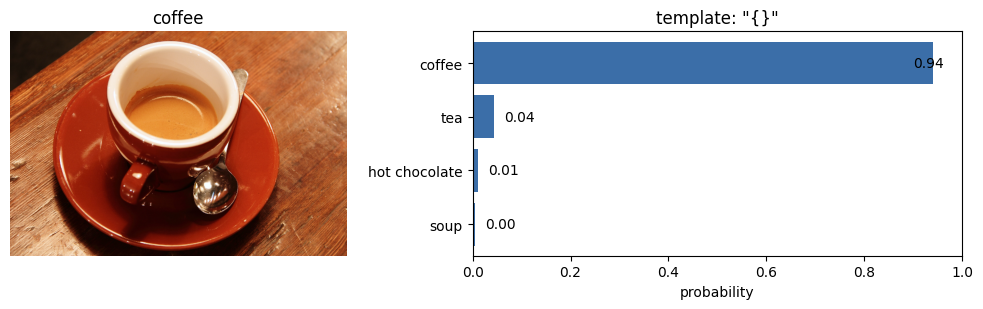

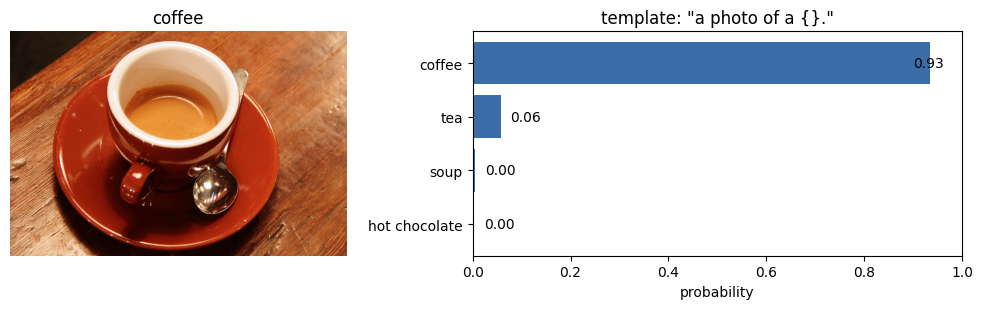

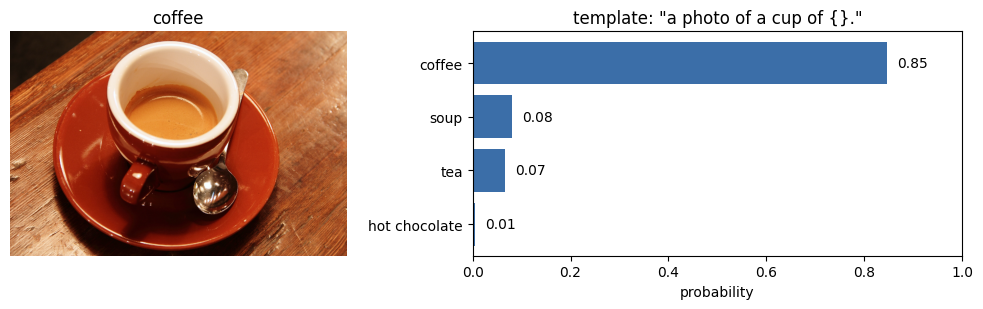

In [11]:
labels = ["coffee", "tea", "soup", "hot chocolate"]
for t in ["{}", "a photo of a {}.", "a photo of a cup of {}."]:
    show_zero_shot(images["coffee"], labels, template=t, title="coffee")

In [12]:
def zero_shot_ensemble(image, labels, templates):
    img_emb = clip_embed_images([image])
    class_embs = []
    for l in labels:
        e = clip_embed_texts([t.format(l) for t in templates]).mean(0)   # average over templates
        class_embs.append(F.normalize(e, dim=-1))
    txt_emb = torch.stack(class_embs)
    return (clip_model.logit_scale.exp() * img_emb @ txt_emb.T).softmax(-1)[0].cpu().numpy()

templates = ["a photo of a {}.", "a close-up photo of a {}.", "a good photo of a {}.",
             "a cropped photo of a {}.", "a picture of a {}."]
print(dict(zip(labels, zero_shot_ensemble(images["coffee"], labels, templates).round(3))))

{'coffee': np.float32(0.925), 'tea': np.float32(0.066), 'soup': np.float32(0.005), 'hot chocolate': np.float32(0.004)}


### 1.4 Same embedding space → text-to-image search
Because images and text live in the same space we can also go the other way: type a query and rank images.
This is the core of modern image search engines and of "retrieval" for multimodal LLMs.

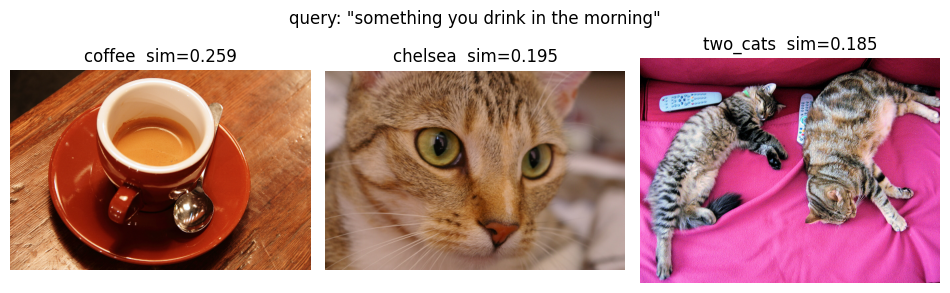

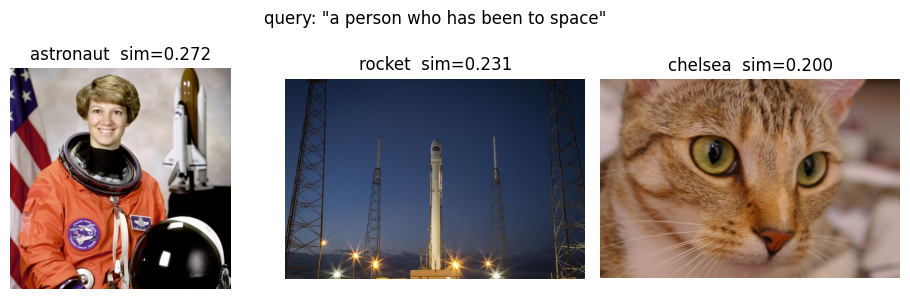

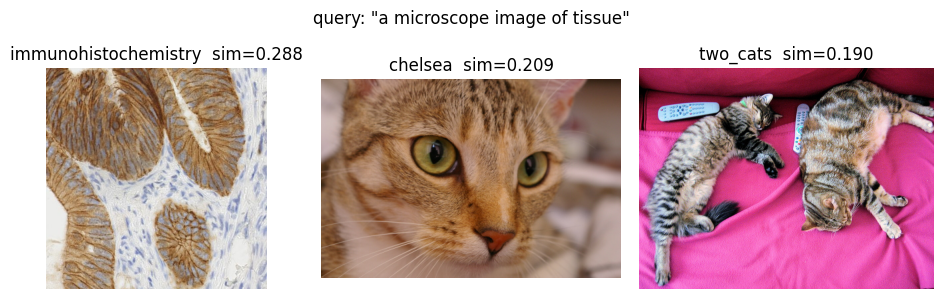

In [13]:
names = list(images.keys())
gallery = clip_embed_images([images[n] for n in names])        # (N, D)

def search(query, k=3):
    q = clip_embed_texts([query])                                # (1, D)
    sims = (q @ gallery.T)[0].cpu().numpy()
    best = np.argsort(-sims)[:k]
    fig, axes = plt.subplots(1, k, figsize=(3.2 * k, 3))
    for ax, i in zip(axes, best):
        ax.imshow(images[names[i]]); ax.axis("off"); ax.set_title(f"{names[i]}  sim={sims[i]:.3f}")
    fig.suptitle(f'query: "{query}"'); plt.tight_layout(); plt.show()

search("something you drink in the morning")
search("a person who has been to space")
search("a microscope image of tissue")

### 1.5 Limits of zero-shot CLIP (discussion)
Try these and discuss what happens.

* **Domain shift.** The `immunohistochemistry` image is a medical microscopy image. Ask CLIP whether it shows `"healthy tissue"` vs `"tumour tissue"`. The answer looks confident, but it is essentially random. CLIP saw very few such images with expert captions. Domain-specific versions exist (BiomedCLIP, PLIP for pathology, CONCH).
* **Softmax always sums to 1.** If you only give `["cat", "dog"]` for the coffee image, CLIP still picks one. Add an `"other"`-style option or look at raw similarities.
* **Counting and spatial relations** (`"cat left of a remote"`) are notoriously weak.
* **Typographic attacks.** A piece of paper with the word "iPod" stuck on an apple makes CLIP say "iPod".

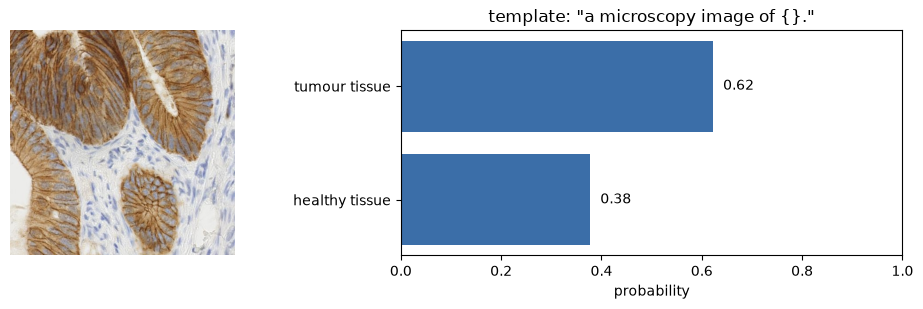

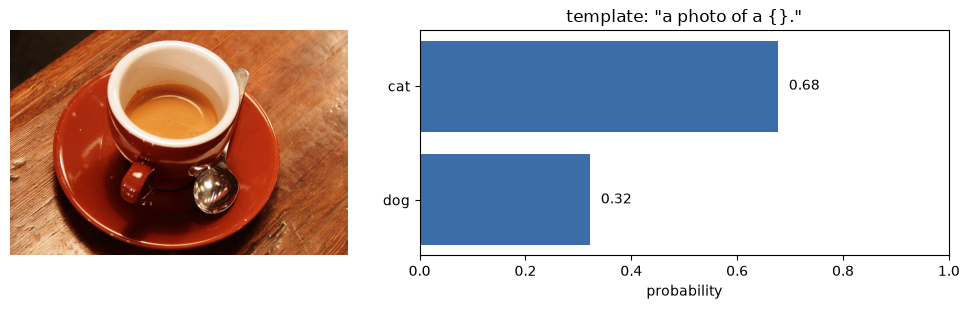

In [11]:
show_zero_shot(images["immunohistochemistry"], ["healthy tissue", "tumour tissue"],
               template="a microscopy image of {}.")
show_zero_shot(images["coffee"], ["cat", "dog"])   # forced choice

**Exercise 1.** Build a zero-shot classifier for 10 classes of your choice and test it on 5 of your own photos. Which prompts work best?

**Exercise 2.** Compare `openai/clip-vit-base-patch32` with `openai/clip-vit-large-patch14` (bigger, slower, better) on the same images.